<a href="https://colab.research.google.com/github/Bhuvibagga/PES2UG24CS117-VDUI-UNIT4/blob/ppt4-branch/Unit4_ppt4activity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Activity: Should We Trust the Alarm? — FreshKart Cold-Chain Case

**Unit 4 · AI-Assisted Visualization · AI-Assisted Pattern and Anomaly Visualization**
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

---

## The case

FreshKart's dark stores keep frozen food in **8 freezers** (one per store in Bengaluru, Pune and Hyderabad). Each freezer reports its temperature every hour. Last month FreshKart bought **ColdSense**, an AI service that scores every reading for "anomaly" and raises an alert when the score is **≥ 0.5**.

Cold-chain lead **Ravi** has six weeks of readings, the ColdSense scores, and the **maintenance log** (what technicians actually found). His technicians are tired of being sent out at night. He asks:

> *"Is ColdSense's alert feed trustworthy? Which alerts should my team chase, and what is it missing?"*

**You are the analyst.** Use the data and the visualizations to verify, correct or reject what the vendor claims.

**Ground rules (from the lecture):** an AI score is a *derived attribute*: look at it, don't only threshold it · flags are **candidates, not conclusions** · report precision and recall, not accuracy · scale emphasis to confidence.

**How to work:** run the notebook top to bottom. Complete every cell marked `# TODO` (replace `None` with your code or answer) and write in the cells marked **✏️ Your answer**. Cells that depend on your TODO will tell you if something is still missing.

### The data: `freshkart_coldchain.csv` (synthetic)

| Column | Meaning |
|---|---|
| `timestamp` | hour of the reading (1 Aug – 11 Sep 2026) |
| `city`, `store_id`, `freezer_id` | where the freezer is |
| `temp_c` | freezer temperature (°C); normal is about −18 °C |
| `door_opens` | number of door openings in that hour (busy by day, quiet at night) |
| `compressor_kw` | compressor power draw (kW) |
| `ai_score`, `ai_flag` | ColdSense anomaly score (0–1) and alert (1 if score ≥ 0.5) |
| `confirmed_fault`, `fault_type` | from the maintenance log: 1 if technicians confirmed a real fault in that hour, and what it was |

**Domain note from the maintenance team:** every freezer runs an automatic **defrost cycle from 02:00 to 04:00** each night. The heater warms the coil, so the temperature rises for those two hours. That is normal.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})
GREY, ACCENT, BLUE = "#bdbdbd", "#d95f02", "#4c78a8"

def ready(*vals):
    """Helper: tells you if a TODO above is still unanswered."""
    ok = all(v is not None for v in vals)
    if not ok:
        print("⚠ Complete the TODO cell(s) above first, then re-run this cell.")
    return ok

df = pd.read_csv("freshkart_coldchain.csv", parse_dates=["timestamp"])
df["hour"] = df["timestamp"].dt.hour
df.head()

,timestamp,city,store_id,freezer_id,temp_c,door_opens,compressor_kw,ai_score,ai_flag,confirmed_fault,fault_type,hour
0,2026-08-01,Bengaluru,B1,FZ-B1,-18.1,0,1.29,0.000,0,0,NaN,0
1,2026-08-01,Bengaluru,B2,FZ-B2,-18.7,0,1.16,0.000,0,0,NaN,0
2,2026-08-01,Bengaluru,B3,FZ-B3,-17.7,0,1.21,0.000,0,0,NaN,0
3,2026-08-01,Hyderabad,H1,FZ-H1,-17.8,0,1.30,0.037,0,0,NaN,0
4,2026-08-01,Hyderabad,H2,FZ-H2,-18.2,0,1.32,0.035,0,0,NaN,0


## ColdSense's monthly report (to be validated)

| # | Vendor statement |
|---|---|
| 1 | "ColdSense is **97.9% accurate**, so its alerts can be trusted." |
| 2 | "**Most faults happen around 2 am.** We recommend a night technician." |
| 3 | "**All 10 compressor trips** in the period were caught." |
| 4 | "Freezer **FZ-H2 ran without a single fault** in August." |
| 5 | "A reading of **−14 °C is abnormal** for any freezer, at any time." |
| 6 | "An alert with a score of **0.92 means a 92% chance** of a real fault." |
| 7 | "The **default threshold of 0.5** is the best setting for FreshKart." |
| 8 | "A new FZ-B1 reading of **−15.9 °C at 14:00** is **15 standard errors** above normal: a definite fault." |

---
## Part 1 · Data abstraction: items, attributes and derived attributes

Munzner: before choosing a view, ask what the **items** and **attributes** are. The AI does not change the items; it **derives** new attributes.

In [2]:
derived_cols = ["ai_score", "ai_flag"]
n_alerts = int((df.ai_flag == 1).sum())
fault_rate_pct = round(df.confirmed_fault.mean() * 100, 2)
if ready(derived_cols, n_alerts, fault_rate_pct):
    print(f"derived: {derived_cols} | alerts: {n_alerts} | faults: {df.confirmed_fault.sum()} of {len(df)} rows ({fault_rate_pct}%)")
    display(df[df.confirmed_fault == 1].groupby("fault_type").size().rename("fault hours"))

derived: ['ai_score', 'ai_flag'] | alerts: 159 | faults: 46 of 8064 rows (0.57%)


,fault hours
fault_type,
compressor trip,10
defrost heater stuck,11
sensor frozen,25


**✏️ Your answer (Part 1):** `ai_score` is quantitative and `ai_flag` is binary. Which **visual channel** suits each, and what information does the flag throw away that the score keeps?

*Your answer:*
Use a sequential colour scale or quantitative position for ai_score; use a distinct categorical marker/colour for binary ai_flag. The flag discards the score's ranking and degree of anomaly: all readings at or above 0.5 look identical.

---
## Part 2 · Distributions: bin width and the score distribution

### 2a · Temperature histogram

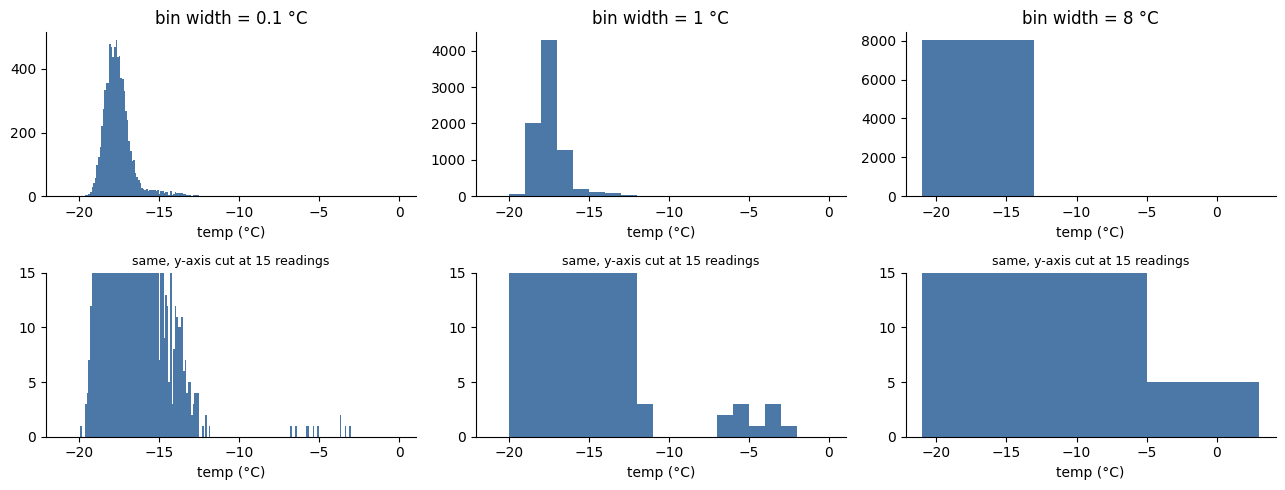

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(13, 5))
for col, w in enumerate([0.1, 1, 8]):
    for row, top in enumerate([None, 15]):
        ax = axes[row, col]
        ax.hist(df["temp_c"], bins=np.arange(-21, 0 + w, w), color=BLUE)
        if top: ax.set_ylim(0, top); ax.set_title(f"same, y-axis cut at {top} readings", fontsize=9)
        else: ax.set_title(f"bin width = {w} °C")
        ax.set_xlabel("temp (°C)")
plt.tight_layout(); plt.show()

warm_tail_visible_bins = [0.1, 1]
n_warm_readings = int((df["temp_c"] > -8).sum())

### 2b · Look at the AI scores before trusting the cut-off
Wilke: compare groups with overlapping densities, not stacked histograms.

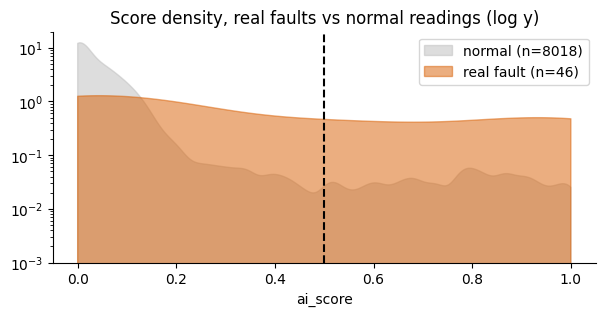

In [4]:
xs = np.linspace(0, 1, 300)
fig, ax = plt.subplots(figsize=(7, 3))
for lab, col in [(0, GREY), (1, ACCENT)]:
    s = df.loc[df.confirmed_fault == lab, "ai_score"]
    ax.fill_between(xs, stats.gaussian_kde(s)(xs), color=col, alpha=.5, label=f"{'real fault' if lab else 'normal'} (n={len(s)})")
ax.axvline(0.5, color="k", ls="--"); ax.set_yscale("log"); ax.set_ylim(1e-3, 20)
ax.set_xlabel("ai_score"); ax.legend(); ax.set_title("Score density, real faults vs normal readings (log y)")
plt.show()

scores_separate_faults = False

**✏️ Your answer (Part 2):** Why is a histogram "a parameterised algorithm", and what would you tell a colleague who says *"the 8 °C histogram shows no anomalies"*?

*Your answer:*
A histogram is a parameterised algorithm because bin width and bin boundaries determine how values are grouped and therefore which patterns appear. The 8 °C bins are too broad and can merge warm readings with the main distribution; I would compare finer bin widths and inspect the underlying readings before concluding that there are no anomalies.

---
## Part 3 · Outlier rules on a short window (vendor statement 3)

Ten consecutive readings from **FZ-P1**, 12 Aug 06:00–15:00. One of them is a compressor trip.

In [5]:
window = df[(df.freezer_id == "FZ-P1") & (df.timestamp >= "2026-08-12 06:00") & (df.timestamp < "2026-08-12 16:00")]
v = window["temp_c"].values
print(window[["timestamp", "temp_c", "fault_type"]].to_string(index=False))

z_max = float(np.max(np.abs((v - np.mean(v)) / np.std(v, ddof=1))))
q1, q3 = np.percentile(v, [25, 75])
upper_fence = float(q3 + 1.5 * (q3 - q1))

if ready(z_max, upper_fence):
    print(f"largest |z| = {z_max:.2f} -> flagged by |z| > 3? {z_max > 3}")
    print(f"upper IQR fence = {upper_fence:.2f} °C -> trip flagged by IQR rule? {v.max() > upper_fence}")
    print(f"largest |z| possible with n = {len(v)}: {(len(v) - 1) / np.sqrt(len(v)):.2f}")

          timestamp  temp_c      fault_type
2026-08-12 06:00:00   -17.5             NaN
2026-08-12 07:00:00   -18.2             NaN
2026-08-12 08:00:00   -17.4             NaN
2026-08-12 09:00:00   -17.7             NaN
2026-08-12 10:00:00   -16.6             NaN
2026-08-12 11:00:00    -3.6 compressor trip
2026-08-12 12:00:00   -17.0             NaN
2026-08-12 13:00:00   -16.8             NaN
2026-08-12 14:00:00   -17.7             NaN
2026-08-12 15:00:00   -17.7             NaN
largest |z| = 2.83 -> flagged by |z| > 3? False
upper IQR fence = -15.58 °C -> trip flagged by IQR rule? True
largest |z| possible with n = 10: 2.85


**✏️ Your answer (Part 3):** Explain in two sentences why the z-score rule missed the trip here (use the word *masking*) and why the IQR rule did not.

*Your answer:*
The extreme trip is partly hidden by masking because it also shifts the mean and standard deviation; with only ten observations, the largest possible absolute sample z-score is about 2.85, below the cutoff of 3. The IQR rule is more resistant to the single extreme value, so its upper fence remains near the normal readings and the trip at −3.6 °C exceeds that fence.

---
## Part 4 · How good is ColdSense? (vendor statement 1)

In [6]:
flag = df.ai_flag == 1
real = df.confirmed_fault == 1
TP = int((flag & real).sum()); FP = int((flag & ~real).sum())
FN = int((~flag & real).sum()); TN = int((~flag & ~real).sum())
if ready(TP, FP, FN, TN):
    display(pd.DataFrame([[TP, FN], [FP, TN]], index=["real fault", "normal"], columns=["alert", "no alert"]))

,alert,no alert
real fault,16,30
normal,143,7875


In [7]:
precision = TP / (TP + FP)
recall = TP / (TP + FN)
f1 = 2 * precision * recall / (precision + recall)
accuracy = (TP + TN) / len(df)
flag_nothing_accuracy = TN / len(df)
if ready(precision, recall, f1, accuracy, flag_nothing_accuracy):
    print(f"precision = {precision:.2f} | recall = {recall:.2f} | F1 = {f1:.2f} | accuracy = {accuracy:.1%} | never-alert accuracy = {flag_nothing_accuracy:.1%}")

precision = 0.10 | recall = 0.35 | F1 = 0.16 | accuracy = 97.9% | never-alert accuracy = 97.7%


**✏️ Your answer (Part 4):** Rewrite vendor statement 1 so it is honest. Use precision and recall, and say in plain words what they mean for Ravi's technicians (how many call-outs are wasted, how many faults are missed).

*Your answer:*
ColdSense has 97.9% accuracy, but that is misleading because faults are rare. At threshold 0.5, precision is 0.10: about 9 out of 10 call-outs are false alarms (143 of 159 alerts). Recall is 0.35: it catches 16 of 46 confirmed fault readings and misses 30 (about 65%). Ravi should judge it using precision and recall, not accuracy alone.

---
## Part 5 · Thresholds and costs (vendor statement 7)

A missed fault can spoil a freezer of stock (cost ≈ **40** units); a false call-out costs **1** unit of technician time.

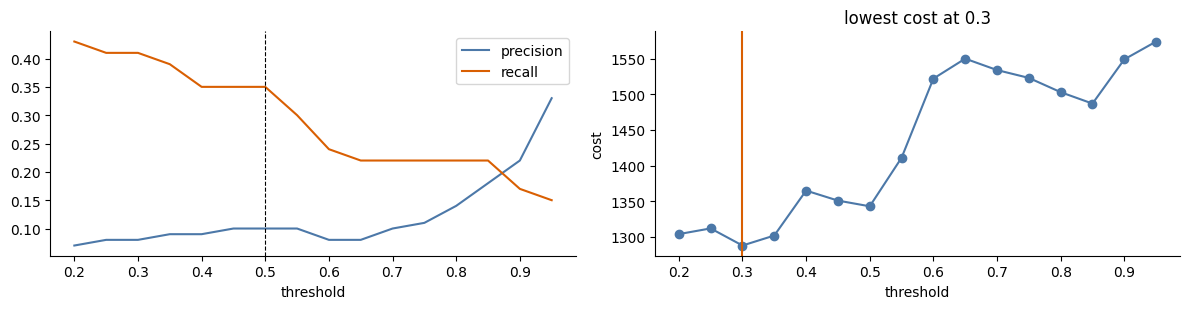

,threshold,TP,FP,FN,precision,recall,cost
0,0.20,20,264,26,0.07,0.43,1304
1,0.25,19,232,27,0.08,0.41,1312
2,0.30,19,208,27,0.08,0.41,1288
3,0.35,18,182,28,0.09,0.39,1302
4,0.40,16,165,30,0.09,0.35,1365
5,0.45,16,151,30,0.10,0.35,1351
6,0.50,16,143,30,0.10,0.35,1343
7,0.55,14,131,32,0.10,0.30,1411
8,0.60,11,122,35,0.08,0.24,1522
9,0.65,10,110,36,0.08,0.22,1550


In [8]:
grid = np.round(np.arange(0.20, 0.96, 0.05), 2)
sweep = pd.DataFrame({"threshold": grid})
sweep["TP"] = [((df.ai_score >= g) & real).sum() for g in grid]
sweep["FP"] = [((df.ai_score >= g) & ~real).sum() for g in grid]
sweep["FN"] = real.sum() - sweep["TP"]
sweep["precision"] = (sweep.TP / (sweep.TP + sweep.FP)).round(2)
sweep["recall"] = (sweep.TP / real.sum()).round(2)

sweep["cost"] = 40 * sweep["FN"] + sweep["FP"]
best_threshold = float(sweep.loc[sweep["cost"].idxmin(), "threshold"])

if ready(best_threshold) and sweep["cost"].notna().all():
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
    ax[0].plot(sweep.threshold, sweep.precision, color=BLUE, label="precision"); ax[0].plot(sweep.threshold, sweep.recall, color=ACCENT, label="recall")
    ax[0].axvline(0.5, color="k", ls="--", lw=.8); ax[0].legend(); ax[0].set_xlabel("threshold")
    ax[1].plot(sweep.threshold, sweep.cost.astype(float), color=BLUE, marker="o"); ax[1].axvline(best_threshold, color=ACCENT)
    ax[1].set_xlabel("threshold"); ax[1].set_ylabel("cost"); ax[1].set_title(f"lowest cost at {best_threshold}")
    plt.tight_layout(); plt.show()
    display(sweep)

**✏️ Your answer (Part 5):** Even at the best threshold, recall stays low. Why can no threshold fix this detector? (Hint: look at *which* faults are never scored high.)

*Your answer:*
ColdSense never gives a high score to sensor-frozen faults: all 25 confirmed sensor-frozen readings have scores below 0.5. No threshold can recover faults whose scores remain near zero; the detector needs to examine a sequence and identify a flat, unchanging sensor pattern.

---
## Part 6 · Where do the errors come from?

### 6a · When do the false alarms happen? (vendor statement 2)

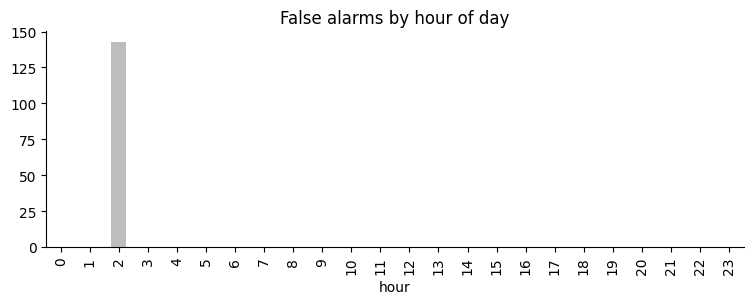

100% of false alarms happen at 2:00


In [9]:
fp_rows = df[flag & ~real]
fp_rows.groupby("hour").size().reindex(range(24), fill_value=0).plot.bar(color=GREY, title="False alarms by hour of day", figsize=(9, 2.8))
plt.show()
fp_peak_hour = int(fp_rows.groupby("hour").size().idxmax())
fp_share_at_peak = float((fp_rows.hour == fp_peak_hour).mean())
if ready(fp_peak_hour, fp_share_at_peak):
    print(f"{fp_share_at_peak:.0%} of false alarms happen at {fp_peak_hour}:00")

### 6b · Which faults does ColdSense miss?

In [10]:
caught = df[real].groupby("fault_type")["ai_flag"].agg(caught="sum", fault_hours="size")
caught["recall"] = (caught.caught / caught.fault_hours).round(2)
display(caught)

never_caught_type = "sensor frozen"
anomaly_kind = "collective"

,caught,fault_hours,recall
fault_type,,,
compressor trip,10,10,1.00
defrost heater stuck,6,11,0.55
sensor frozen,0,25,0.00


### 6c · Contextual anomalies: compare each reading with its own hour

A **context-aware** baseline compares each reading with the same freezer at the same hour of day (median and MAD over the six weeks).

In [11]:
grp = df.groupby(["freezer_id", "hour"])["temp_c"]
df["hour_median"] = grp.transform("median")
df["hour_mad"] = grp.transform(lambda s: 1.4826 * stats.median_abs_deviation(s))

df["z_context"] = (df["temp_c"] - df["hour_median"]) / df["hour_mad"].replace(0, np.nan)

if ready(*df["z_context"].head(1)):
    ctx_flag = df["z_context"].astype(float) > 4
    found = df[real & ctx_flag & ~flag]
    print(f"Real faults the context baseline catches but ColdSense missed: {len(found)}")
    display(found[["timestamp", "freezer_id", "temp_c", "hour_median", "z_context", "ai_score", "fault_type"]])
    print(f"False alarms at 02:00 under the context baseline: {(ctx_flag & ~real & (df.hour == 2)).sum()} (ColdSense: {(flag & ~real & (df.hour == 2)).sum()})")

Real faults the context baseline catches but ColdSense missed: 3


,timestamp,freezer_id,temp_c,hour_median,z_context,ai_score,fault_type
1279,2026-08-07 15:00:00,FZ-P2,-14.6,-17.50,4.890058,0.369,defrost heater stuck
4731,2026-08-25 15:00:00,FZ-H1,-14.8,-17.50,6.070417,0.388,defrost heater stuck
6273,2026-09-02 16:00:00,FZ-B2,-15.2,-17.35,4.143300,0.189,defrost heater stuck


False alarms at 02:00 under the context baseline: 0 (ColdSense: 143)


### 6d · Collective anomalies: a run of readings that is abnormal together

                           min                 max  count
freezer_id                                               
FZ-H2      2026-08-20 14:00:00 2026-08-20 22:00:00      9
FZ-P1      2026-09-06 12:00:00 2026-09-06 17:00:00      6


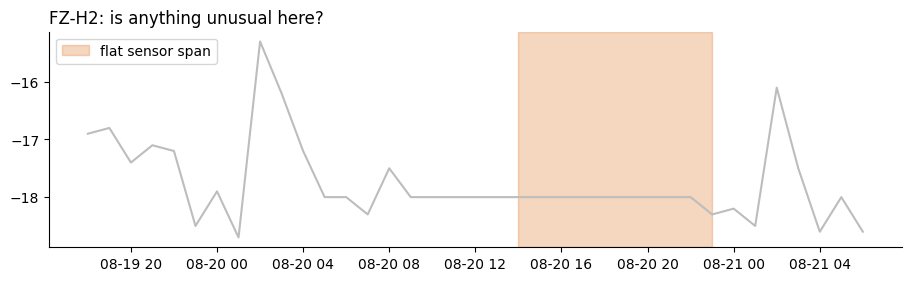

In [12]:
df = df.sort_values(["freezer_id", "timestamp"])
df["roll_sd_6h"] = df.groupby("freezer_id")["temp_c"].transform(lambda s: s.rolling(6).std())

flat = df[df["roll_sd_6h"] < 0.01].copy()

if ready(flat):
    print(flat.groupby("freezer_id")["timestamp"].agg(["min", "max", "count"]))
    h2 = df[(df.freezer_id == "FZ-H2") & (df.timestamp.between("2026-08-19 18:00", "2026-08-21 06:00"))]
    fig, ax = plt.subplots(figsize=(11, 2.8))
    ax.plot(h2.timestamp, h2.temp_c, color=GREY)
    h2_flat = flat[flat["freezer_id"] == "FZ-H2"]
    if not h2_flat.empty:
        start = h2_flat["timestamp"].min()
        end = h2_flat["timestamp"].max() + pd.Timedelta(hours=1)
        ax.axvspan(start, end, color=ACCENT, alpha=.25, label="flat sensor span")
        ax.legend(loc="upper left")

    ax.set_title("FZ-H2: is anything unusual here?", loc="left"); plt.show()
df = df.sort_values(["timestamp", "store_id"])

**✏️ Your answer (Part 6):**
(a) Rewrite vendor statement 2. What really happens at 2 am, and what would happen if FreshKart hired a night technician based on the vendor's report?
(b) Is vendor statement 5 true? Use the words *contextual anomaly* and say what a chart must show for a viewer to judge such an alert.
(c) What is wrong with vendor statement 4, and why can a detector that scores readings one at a time never catch this kind of fault?

*Your answer:*

(a) All 143 false alarms occur at 02:00 during the scheduled 02:00–04:00 defrost cycle; this does not show that most faults happen at 2 am. Hiring a night technician from this report would cause unnecessary call-outs to investigate normal warming.
(b) No. −14 °C is not always abnormal; it can be a contextual anomaly depending on the freezer and hour. A chart should show the reading in a time series alongside that freezer's normal range for the same hour.
(c) FZ-H2 did have confirmed sensor-frozen faults in August. A detector scoring readings one at a time may treat each repeated −18 °C value as normal; it must inspect the sequence to detect the collective flatline pattern.

---
## Part 7 · Highlighting, saliency and frequency framing (vendor statement 6)

### 7a · Emphasis scaled to confidence
The vendor's dashboard paints every alert bright red. Implement the lecture's checklist: **≥ 0.90 strong**, **0.70–0.90 moderate**, **0.50–0.70 subtle outline**, **below 0.50 no emphasis** (the data stays visible).

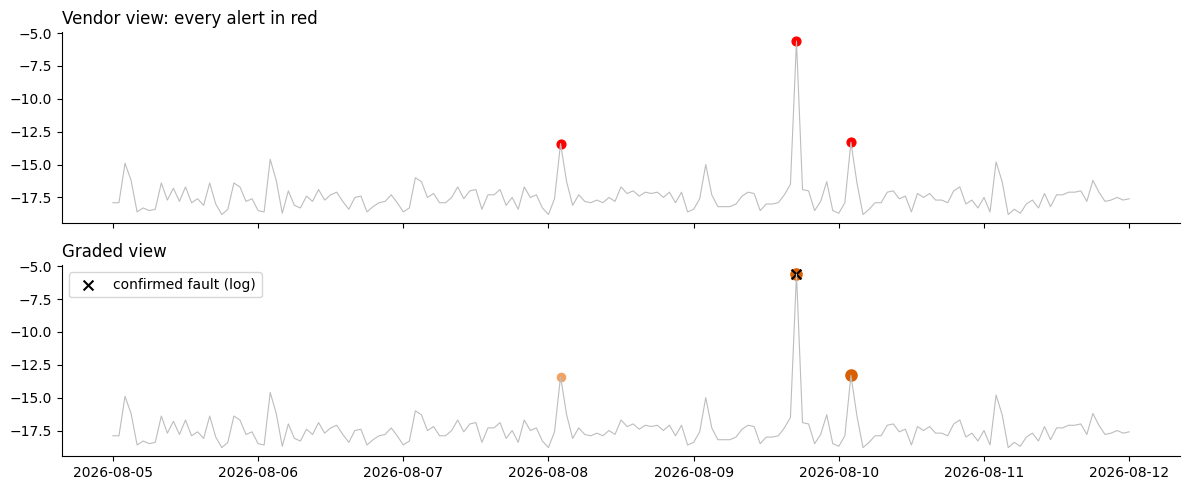

In [13]:
def emphasis(score):
    """Return (colour, marker size, edge colour) for one reading."""
    if score >= 0.90: return (ACCENT, 65, ACCENT)
    elif score >= 0.70: return ("#f4a261", 35, "#f4a261")
    elif score >= 0.50: return ("white", 22, ACCENT)
    else: return ("white", 0, "white")

week = df[(df.freezer_id == "FZ-B2") & (df.timestamp.between("2026-08-05", "2026-08-12"))]
if ready(emphasis(0.95)):
    fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
    ax[0].plot(week.timestamp, week.temp_c, color=GREY, lw=.8)
    a = week[week.ai_flag == 1]; ax[0].scatter(a.timestamp, a.temp_c, color="red", s=40); ax[0].set_title("Vendor view: every alert in red", loc="left")
    ax[1].plot(week.timestamp, week.temp_c, color=GREY, lw=.8)
    for _, r in week[week.ai_score >= 0.5].iterrows():
        col, size, edge = emphasis(r.ai_score)
        ax[1].scatter(r.timestamp, r.temp_c, color=col, s=size, edgecolors=edge)
    f_ = week[week.confirmed_fault == 1]; ax[1].scatter(f_.timestamp, f_.temp_c, marker="x", color="k", s=50, label="confirmed fault (log)")
    ax[1].legend(loc="upper left"); ax[1].set_title("Graded view", loc="left"); plt.tight_layout(); plt.show()

### 7b · "A score of 0.92 means 92%"? Count it.
Wilke: people read probabilities better as **frequencies**. Of all alerts in a score band, how many were real?

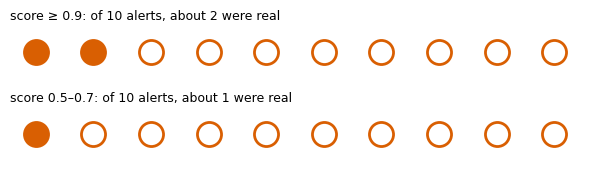

In [14]:
band_hi = df[df.ai_score >= 0.9]
band_lo = df[(df.ai_score >= 0.5) & (df.ai_score < 0.7)]

real_per_10_hi = int(round(band_hi["confirmed_fault"].mean() * 10))
real_per_10_lo = int(round(band_lo["confirmed_fault"].mean() * 10))

if ready(real_per_10_hi, real_per_10_lo):
    fig, ax = plt.subplots(2, 1, figsize=(6, 1.8))
    for a_, k, lab in zip(ax, [real_per_10_hi, real_per_10_lo], ["score ≥ 0.9", "score 0.5–0.7"]):
        for i in range(10): a_.scatter(i, 0, s=300, color=ACCENT if i < k else "white", edgecolors=ACCENT, linewidths=2)
        a_.axis("off"); a_.set_title(f"{lab}: of 10 alerts, about {k} were real", loc="left", fontsize=9)
    plt.tight_layout(); plt.show()

**✏️ Your answer (Part 7):** (a) Why does a red dot at every alert make Ravi's team **more** likely to miss the frozen H2 sensor? Use the words *salience* and *inattentional blindness*. (b) Rewrite vendor statement 6 using frequency framing.

*Your answer:*
(a) When every alert is bright red, all alerts compete for salience and technicians become used to seeing red dots. Attention is drawn to repeated defrost false alarms, increasing inattentional blindness to a less obvious pattern such as the frozen H2 sensor. (b) A score of 0.92 is not a 92% probability: in this dataset, only about 2 out of 10 alerts with scores at least 0.90 are confirmed faults

---
## Part 8 · Standard deviation vs standard error (vendor statement 8)

The vendor judged a new FZ-B1 reading of **−15.9 °C at 14:00** against the 14:00 baseline.

In [15]:
base = df[(df.freezer_id == "FZ-B1") & (df.hour == 14) & (df.confirmed_fault == 0)]["temp_c"]
mu, sd, n = base.mean(), base.std(), len(base)
new_reading = -15.9

se = sd / np.sqrt(n)
z_sd = (new_reading - mu) / sd
z_se = (new_reading - mu) / se

if ready(se, z_sd, z_se):
    print(f"baseline: mean {mu:.2f} °C, SD {sd:.2f}, n = {n}, SE = {se:.3f}")
    print(f"z using SD = {z_sd:.1f} | z using SE = {z_se:.1f}")

correct_z = "SD"

baseline: mean -17.31 °C, SD 0.61, n = 42, SE = 0.094
z using SD = 2.3 | z using SE = 15.0


**✏️ Your answer (Part 8):** In one sentence each, say what the SD and the SE describe, and rewrite vendor statement 8.

*Your answer:*
The SD describes the spread of individual normal readings around their mean, while the SE describes uncertainty in the estimated mean. Vendor statement 8 misuses SE to judge an individual reading: −15.9 °C is about 2.3 SD above the baseline mean, not 15 SD, so this calculation alone does not establish a definite fault.

---
## Part 9 · Triage the vendor report

For each statement decide: **Accept** (correct as stated), **Correct** (useful, but the wording or number must change) or **Reject** (not supported). Then measure the report.

In [16]:
decisions = {1:"Correct", 2:"Reject", 3:"Accept", 4:"Reject", 5:"Correct", 6:"Correct", 7:"Correct", 8:"Correct"}
if all(v in ("Accept", "Correct", "Reject") for v in decisions.values()):
    accepted = sum(v == "Accept" for v in decisions.values())
    print(f"Statements accepted as written: {accepted}/{len(decisions)} ({accepted / len(decisions):.0%})")
    print(pd.Series(decisions).value_counts().to_string())
else:
    print("⚠ Fill in all eight decisions with 'Accept', 'Correct' or 'Reject'.")

Statements accepted as written: 1/8 (12%)
Correct    5
Reject     2
Accept     1


**✏️ Your answer (Part 9):** Sketch (in words or a quick drawing) the **anomaly review view** you would give Ravi's team instead of the vendor's red-dot dashboard. Name at least four parts: main view, context, queue, verification tools, evaluation.

*Your answer:*
I would design a review dashboard with five parts: (1) Main view: a temperature time-series for the selected freezer, with fault events and graded alert emphasis rather than identical red dots. (2) Context: the freezer's normal operating band for that hour, with the scheduled 02:00–04:00 defrost period shaded. (3) Review queue: alerts ranked by score and persistence, with repeated defrost alerts grouped and flatline sensor warnings surfaced separately. (4) Verification tools: inspect raw readings, door openings, compressor power, maintenance notes and neighbouring hours, then mark an alert confirmed, false or unresolved. (5) Evaluation: precision, recall, missed faults, false call-outs and threshold/cost trade-offs by fault type and store.

---
## Reflection

Answer in 2–4 sentences each. There are no right-or-wrong answers here; we are looking for honest thinking about *your own* process.

**1. Automation bias.** Before you checked anything, which vendor statement did you find most convincing? Was it the number, the confident tone, or the red dots? Would you have caught the problem without the maintenance log?

*Your reflection:*
Automation bias. I initially found the 97.9% accuracy claim convincing because it was a precise number and sounded objective. Without the maintenance log, I could not know which readings were confirmed faults or properly measure precision and recall. The labels revealed that high accuracy concealed many missed faults and false alarms.

**2. Who sets the threshold?** The threshold decides how many night call-outs happen and how many freezers spoil. Who at FreshKart should own that choice, and what information should the dashboard show them?

*Your reflection:*
Who sets the threshold? The cold-chain operations lead should own the threshold decision with maintenance and food-safety stakeholders, because they understand the consequences of missed faults and unnecessary call-outs. The dashboard should show precision, recall, false alarms, missed faults, fault types and estimated cost at each threshold. The threshold should be reviewed when operating conditions or costs change.

**3. Missing ground truth.** You had a maintenance log. In real life, faults nobody inspected never get a label. How would that change your precision and recall numbers, and how could the review workflow reduce the problem?

*Your reflection:*
Missing ground truth. If uninspected faults remain labelled as normal, some true positives may be counted as false positives and some missed faults remain hidden, making precision and recall estimates unreliable. The workflow should sample and inspect some unalerted readings as well as alerts, record technician outcomes, and audit uncertain cases. This avoids learning only from the alerts the system already raised.

**4. Designing against over-trust.** Name one design change (encoding, interaction, wording) that would make technicians *check* an alert rather than simply obey or ignore it.

*Your reflection:*
Designing against over-trust. I would label the score as an anomaly score rather than a probability and show each reading against its freezer-and-hour baseline. I would also require technicians to inspect the surrounding time series and maintenance context before marking an alert confirmed or dismissed.